# 1. Objective and Business Context

### Business Problem

Credit risk assessment requires estimating the likelihood that a borrower will fail to meet their payment obligations. This project explores how machine learning can support credit risk analysis using historical credit card client data.

The objective is to develop an explainable and monitorable classification system that estimates the probability of default for an individual client.

### Dataset

The project uses the UCI Default of Credit Card Clients dataset, which contains demographic information, credit limits, repayment history, bill amounts, payment amounts, and an indicator of default payment next month.

### Objectives

- Understand the dataset structure and business meaning of its variables.
- Assess data quality and identify potential issues.
- Explore the distribution of the target variable and explanatory features.
- Investigate relationships between client characteristics and default.
- Document data risks and establish an initial modeling strategy.

### Scope

This notebook focuses on data understanding and exploratory analysis. Model development, evaluation, explainability, and monitoring will be addressed in subsequent stages.

# 2. Data loading

In [1]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# Load the dataset
data_path = '/Users/syryoo/Projects/risklab-credit-risk/data/raw/UCI_Credit_Card.csv'
df = pd.read_csv(data_path)

In [3]:
# Display the shape of the dataset
print(f"The dataset contains {df.shape[0]} rows and {df.shape[1]} columns.")

The dataset contains 30000 rows and 25 columns.


In [4]:
# Display the first 5 rows of the dataset
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [5]:
# Display the column names of the dataset
df.columns

Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6',
       'default.payment.next.month'],
      dtype='str')

In [6]:
# Display the information about the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2                   30000 non-null

# 3. Dataset structure and feature dictionary

The meaning of the variables of the dataset can be found in [this discussion post of the corresponding Kaggle repository](https://www.kaggle.com/datasets/uciml/default-of-credit-card-clients-dataset/discussion/34608):

* `ID`: ID of each client
* `LIMIT_BAL`: Amount of given credit in NT dollars (includes individual and family/supplementary credit)
* `SEX`: Gender (1=male, 2=female)
* `EDUCATION`: (1=graduate school, 2=university, 3=high school, 0,4,5,6=others)
* `MARRIAGE`: Marital status (1=married, 2=single, 3=divorced, 0=others)
* `AGE`: Age in years
* `PAY_$N$`: History of past payment. `PAY_0` = the repayment status in September, 2005; `PAY_2` = the repayment status in August, 2005; ...; `PAY_6` = the repayment status in April, 2005. The measurement scale for the repayment status is:

    * -2: No consumption; -1: Paid in full; 0: The use of revolving credit; 1 = payment delay for one month; 2 = payment delay for two months; ...; 8 = payment delay for eight months; 9 = payment delay for nine months and above.

* `BILL_AMT$N$`: Amount of bill statement (NT dollar). `BILL_AMT1` = amount of bill statement in September, 2005; `BILL_AMT2` = amount of bill statement in August, 2005; ...; `BILL_AMT6` = amount of bill statement in April, 2005.
* `PAY_AMT$N$`: Amount of previous payment (NT dollar). `PAY_AMT1` = amount paid in September, 2005; `PAY_AMT2` = amount paid in August, 2005; ...; `PAY_AMT6` = amount paid in April, 2005.

If we group the columns by their meanings, we can categorize them as follows:

* Identifier: `ID`
* Demographics: `LIMIT_BAL`, `SEX`, `EDUCATION`, `MARRIAGE`, `AGE`
* Repayment history: `PAY_0`, `PAY_2`, `PAY_3`, `PAY_4`, `PAY_5`, `PAY_6`
* Bill amounts: `BILL_AMT1`, `BILL_AMT2`, `BILL_AMT3`, `BILL_AMT4`, `BILL_AMT5`, `BILL_AMT6`
* Payment amounts: `PAY_AMT1`, `PAY_AMT2`, `PAY_AMT3`, `PAY_AMT4`, `PAY_AMT5`, `PAY_AMT6`
* Target variable: `default.payment.next.month`

In [7]:
# Display the data types of the columns of each group defined above.

print("Identifier:")
print(df[['ID']].dtypes)

print("\nDemographics:")
print(df[['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE']].dtypes)

print("\nRepayment history:")
print(df[['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']].dtypes)

Identifier:
ID    int64
dtype: object

Demographics:
LIMIT_BAL    float64
SEX            int64
EDUCATION      int64
MARRIAGE       int64
AGE            int64
dtype: object

Repayment history:
PAY_0    int64
PAY_2    int64
PAY_3    int64
PAY_4    int64
PAY_5    int64
PAY_6    int64
dtype: object


In [8]:
print("\nBill amounts:")
print(df[['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']].dtypes)

print("\nPayment amounts:")
print(df[['PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']].dtypes)

print("\nTarget variable:")
print(df[['default.payment.next.month']].dtypes)


Bill amounts:
BILL_AMT1    float64
BILL_AMT2    float64
BILL_AMT3    float64
BILL_AMT4    float64
BILL_AMT5    float64
BILL_AMT6    float64
dtype: object

Payment amounts:
PAY_AMT1    float64
PAY_AMT2    float64
PAY_AMT3    float64
PAY_AMT4    float64
PAY_AMT5    float64
PAY_AMT6    float64
dtype: object

Target variable:
default.payment.next.month    int64
dtype: object


In [9]:
# Check the number of unique values in the categorical columns
categorical_columns1 = ['ID', 'SEX', 'EDUCATION', 'MARRIAGE']
for col in categorical_columns1:
    n_unique_values = df[col].nunique()
    unique_values = df[col].unique()
    print(f"Column '{col}' has {n_unique_values} unique values.")
    print(f"The unique values are: {unique_values}\n")

Column 'ID' has 30000 unique values.
The unique values are: [    1     2     3 ... 29998 29999 30000]

Column 'SEX' has 2 unique values.
The unique values are: [2 1]

Column 'EDUCATION' has 7 unique values.
The unique values are: [2 1 3 5 4 6 0]

Column 'MARRIAGE' has 4 unique values.
The unique values are: [1 2 3 0]



The values 0, 4, 5, and 6 in `EDUCATION` mean the same thing, which is "others". Therefore, we can combine them into a single category later.

In [10]:
# Check the number of unique values in the categorical columns
categorical_columns1 = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
for col in categorical_columns1:
    n_unique_values = df[col].nunique()
    unique_values = df[col].unique()
    print(f"Column '{col}' has {n_unique_values} unique values.")
    print(f"The unique values are: {unique_values}\n")

Column 'PAY_0' has 11 unique values.
The unique values are: [ 2 -1  0 -2  1  3  4  8  7  5  6]

Column 'PAY_2' has 11 unique values.
The unique values are: [ 2  0 -1 -2  3  5  7  4  1  6  8]

Column 'PAY_3' has 11 unique values.
The unique values are: [-1  0  2 -2  3  4  6  7  1  5  8]

Column 'PAY_4' has 11 unique values.
The unique values are: [-1  0 -2  2  3  4  5  7  6  1  8]

Column 'PAY_5' has 10 unique values.
The unique values are: [-2  0 -1  2  3  5  4  7  8  6]

Column 'PAY_6' has 10 unique values.
The unique values are: [-2  2  0 -1  3  6  4  7  8  5]



# 4. Data quality assessment

In this section, the following checks are done:

- Existence of data missingness
- Existence of duplicated data
- Occurences of undefined values in categorical features
- Existence of inconsistent values, such as, negative values in amount related variables

In [11]:
# Check the existence of missing values in the dataset
missing_values = df.isna().sum()
print("Missing values in each column:")
print(missing_values)

Missing values in each column:
ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default.payment.next.month    0
dtype: int64


In [12]:
# Check the existence of duplicate rows in the dataset
duplicate_rows = df.duplicated().sum()
print(f"\nThe dataset contains {duplicate_rows} duplicate rows.")


The dataset contains 0 duplicate rows.


We can observe that the payment history columns (`PAY_0` to `PAY_6`) have a significant number of occurrences of the value 0, which may indicate that these columns contain missing or invalid data. Further investigation is needed to understand the implications of these values on the analysis and modeling process.

In [13]:
# Check whether the numerical columns have any inconsistent values (e.g., negative values for amounts)
numerical_columns = ['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']
for col in numerical_columns:
    negative_values = df[df[col] < 0]
    if not negative_values.empty:
        print(f"Column '{col}' has {len(negative_values)} negative values.")
    else:
        print(f"Column '{col}' has no negative values.")

Column 'LIMIT_BAL' has no negative values.
Column 'AGE' has no negative values.
Column 'BILL_AMT1' has 590 negative values.
Column 'BILL_AMT2' has 669 negative values.
Column 'BILL_AMT3' has 655 negative values.
Column 'BILL_AMT4' has 675 negative values.
Column 'BILL_AMT5' has 655 negative values.
Column 'BILL_AMT6' has 688 negative values.
Column 'PAY_AMT1' has no negative values.
Column 'PAY_AMT2' has no negative values.
Column 'PAY_AMT3' has no negative values.
Column 'PAY_AMT4' has no negative values.
Column 'PAY_AMT5' has no negative values.
Column 'PAY_AMT6' has no negative values.


The columns `BILL_AMT1`, `BILL_AMT2`, `BILL_AMT3`, `BILL_AMT4`, `BILL_AMT5`, and `BILL_AMT6` have some negative values, which may indicate refunds or adjustments. Further investigation is needed to understand the context of these negative values and whether they should be treated as valid data points or if they require cleaning or transformation.

In [14]:
# Check if BILL_AMT and LIMIT_BAL columns have any inconsistent values (e.g., BILL_AMT > LIMIT_BAL)
for i in range(1, 7):
    bill_col = f'BILL_AMT{i}'
    inconsistent_values = df[df[bill_col] > df['LIMIT_BAL']]
    if not inconsistent_values.empty:
        print(f"Column '{bill_col}' has {len(inconsistent_values)} inconsistent values (BILL_AMT > LIMIT_BAL).")
    else:
        print(f"Column '{bill_col}' has no inconsistent values (BILL_AMT > LIMIT_BAL).")

Column 'BILL_AMT1' has 2115 inconsistent values (BILL_AMT > LIMIT_BAL).
Column 'BILL_AMT2' has 1940 inconsistent values (BILL_AMT > LIMIT_BAL).
Column 'BILL_AMT3' has 1583 inconsistent values (BILL_AMT > LIMIT_BAL).
Column 'BILL_AMT4' has 1018 inconsistent values (BILL_AMT > LIMIT_BAL).
Column 'BILL_AMT5' has 820 inconsistent values (BILL_AMT > LIMIT_BAL).
Column 'BILL_AMT6' has 798 inconsistent values (BILL_AMT > LIMIT_BAL).


There are values in the `BILL_AMT` columns that are greater than the `LIMIT_BAL` column, which seems inconsistent. This indicates that some customers have billed amounts that exceed their credit limit, which may be an error in the data or an indication of over-limit spending. Further investigation is needed to understand the cause of these inconsistencies and how to handle them in the analysis.

In [15]:
# Check if BILL_AMT and PAY_AMT columns have any inconsistent values (e.g., BILL_AMT < PAY_AMT)
for i in range(1, 7):
    bill_col = f'BILL_AMT{i}'
    pay_col = f'PAY_AMT{i}'
    inconsistent_values = df[df[bill_col] < df[pay_col]]
    if not inconsistent_values.empty:
        print(f"Columns '{bill_col}' and '{pay_col}' have {len(inconsistent_values)} inconsistent values (BILL_AMT < PAY_AMT).")
    else:
        print(f"Columns '{bill_col}' and '{pay_col}' have no inconsistent values (BILL_AMT < PAY_AMT).")

Columns 'BILL_AMT1' and 'PAY_AMT1' have 4330 inconsistent values (BILL_AMT < PAY_AMT).
Columns 'BILL_AMT2' and 'PAY_AMT2' have 4529 inconsistent values (BILL_AMT < PAY_AMT).
Columns 'BILL_AMT3' and 'PAY_AMT3' have 4265 inconsistent values (BILL_AMT < PAY_AMT).
Columns 'BILL_AMT4' and 'PAY_AMT4' have 4096 inconsistent values (BILL_AMT < PAY_AMT).
Columns 'BILL_AMT5' and 'PAY_AMT5' have 4356 inconsistent values (BILL_AMT < PAY_AMT).
Columns 'BILL_AMT6' and 'PAY_AMT6' have 4527 inconsistent values (BILL_AMT < PAY_AMT).


In addition, we also observe that `PAY_AMT` columns can have values greater than `BILL_AMT` columns, which seems to be inconsistent. However, given the fact that customers can make payments that exceed their bill amounts (e.g., paying off previous balances or making advance payments), this may not necessarily be an error. Therefore, we will not treat this as an inconsistency for now, but it is something to keep in mind during further analysis.

# 5. Target variable analysis

We now try to understand the target variable, `default.payment.next.month`.

In [16]:
# Check the number of defaulted and non-defaulted customers
default_counts = df['default.payment.next.month'].value_counts()
print("\nNumber of defaulted and non-defaulted customers:")
print(default_counts)


Number of defaulted and non-defaulted customers:
default.payment.next.month
0    23364
1     6636
Name: count, dtype: int64


In [17]:
# Check the proportion of defaulted and non-defaulted customers
default_props = df['default.payment.next.month'].value_counts(normalize=True)
print("\nProportion of defaulted and non-defaulted customers:")
print(default_props)


Proportion of defaulted and non-defaulted customers:
default.payment.next.month
0    0.7788
1    0.2212
Name: proportion, dtype: float64


<Axes: title={'center': 'Number of Defaulted and Non-Defaulted Customers'}, xlabel='Default Status', ylabel='Count'>

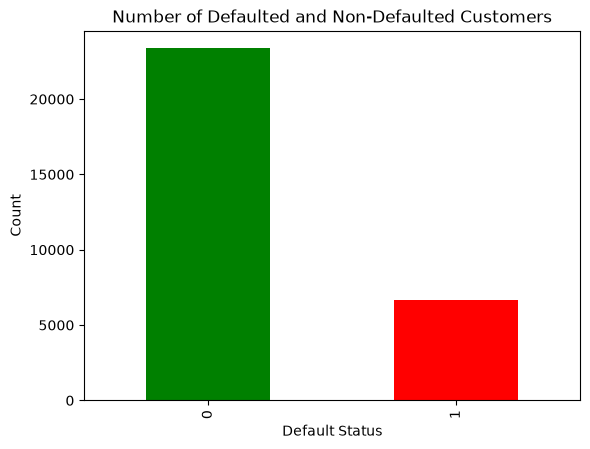

In [18]:
df['default.payment.next.month'].value_counts().plot(kind='bar', color=['green', 'red'], xlabel='Default Status', ylabel='Count', title='Number of Defaulted and Non-Defaulted Customers')

Almost the quarter of the customers in the dataset have defaulted on their payments, with 6,636 out of 30,000 customers defaulting. This indicates that there is an imbalance in the dataset, which may need to be addressed during model training to ensure that the model does not become biased towards the majority class (non-defaulted customers).

# 6. Univariate exploratory data analysis

In this section, we explore the distributions of the individual features.

Text(0, 0.5, 'Frequency')

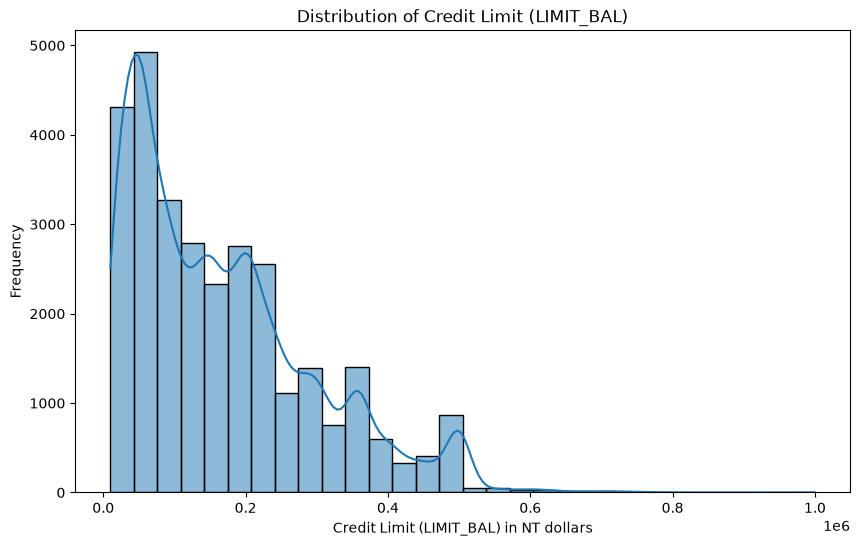

In [19]:
# Explore the distribution of the 'LIMIT_BAL' column
plt.figure(figsize=(10, 6))
sns.histplot(df['LIMIT_BAL'], bins=30, kde=True)
plt.title('Distribution of Credit Limit (LIMIT_BAL)')
plt.xlabel('Credit Limit (LIMIT_BAL) in NT dollars')
plt.ylabel('Frequency') 

The distribution of the `LIMIT_BAL` column shows that most customers have a credit limit below 200,000 NT dollars, with a few customers having significantly higher credit limits. The distribution is right-skewed, indicating that there are more customers with lower credit limits than those with higher credit limits.

Text(0, 0.5, 'Frequency')

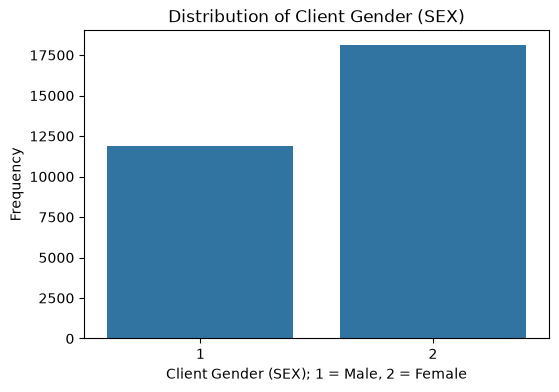

In [20]:
# Explore the distribution of the 'SEX' column
plt.figure(figsize=(6, 4))
sns.countplot(x='SEX', data=df)
plt.title('Distribution of Client Gender (SEX)')
plt.xlabel('Client Gender (SEX); 1 = Male, 2 = Female')
plt.ylabel('Frequency') 

In [21]:
# Compute the proportions of customers in each category of the 'SEX' column
sex_proportions = df['SEX'].value_counts(normalize=True)
print("\nProportions of customers in each category of the 'SEX' column:")
for sex, proportion in sex_proportions.items():
    gender = 'Male' if sex == 1 else 'Female'
    print(f"{gender}: {proportion:.2%}")


Proportions of customers in each category of the 'SEX' column:
Female: 60.37%
Male: 39.63%


There are more females than males in the dataset, with 60% of the clients being female and 40% being male. This indicates that the dataset has a higher representation of female clients compared to male clients.

Text(0, 0.5, 'Frequency')

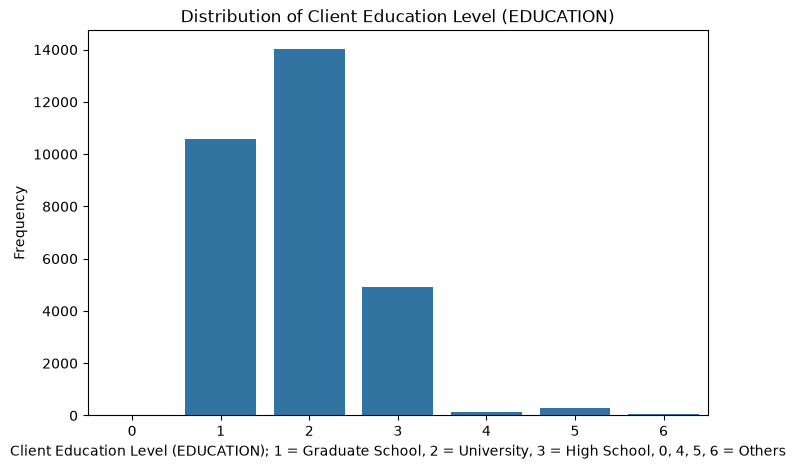

In [22]:
# Check the distribution of the 'EDUCATION' column
plt.figure(figsize=(8, 5))
sns.countplot(x='EDUCATION', data=df)
plt.title('Distribution of Client Education Level (EDUCATION)')
plt.xlabel('Client Education Level (EDUCATION); 1 = Graduate School, 2 = University, 3 = High School, 0, 4, 5, 6 = Others')
plt.ylabel('Frequency')

Most of the customers have an education level of either Graduate School, University, or High School, with a smaller proportion having other education levels. As mentioned before, the categories that represent 'Others' need to be combined into a single category for analysis.

Text(0, 0.5, 'Frequency')

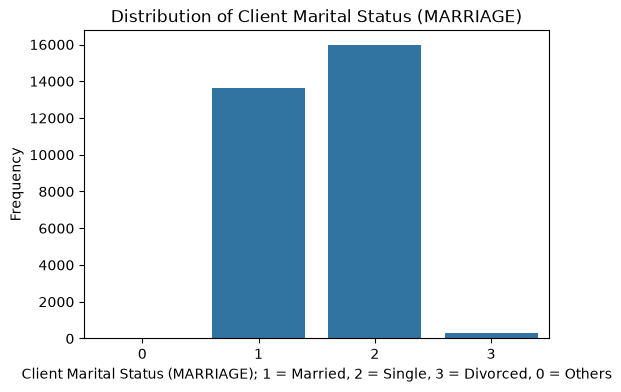

In [23]:
# Explore the distribution of the 'MARRIAGE' column
plt.figure(figsize=(6, 4))
sns.countplot(x='MARRIAGE', data=df)
plt.title('Distribution of Client Marital Status (MARRIAGE)')
plt.xlabel('Client Marital Status (MARRIAGE); 1 = Married, 2 = Single, 3 = Divorced, 0 = Others')
plt.ylabel('Frequency')

In [24]:
# Compute the poroportions of customers in each category of the 'MARRIAGE' column
marriage_proportions = df['MARRIAGE'].value_counts(normalize=True)
print("\nProportions of customers in each category of the 'MARRIAGE' column:")
for marriage, proportion in marriage_proportions.items():
    status = 'Married' if marriage == 1 else 'Single' if marriage == 2 else 'Divorced' if marriage == 3 else 'Others'
    print(f"{status}: {proportion:.2%}") 


Proportions of customers in each category of the 'MARRIAGE' column:
Single: 53.21%
Married: 45.53%
Divorced: 1.08%
Others: 0.18%


More than 50% of the customers are single, while 45% are married, and the remaining 1% fall into either 'Divorced' or 'Others' categories.

Text(0, 0.5, 'Frequency')

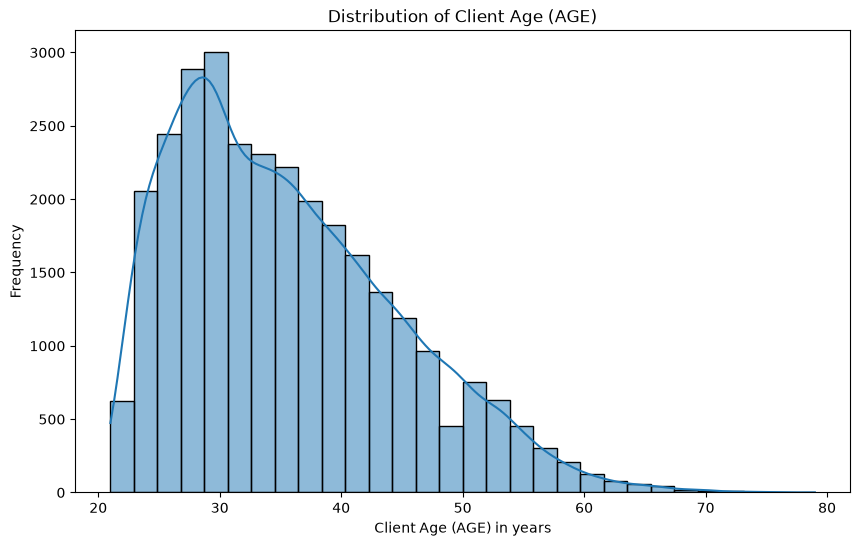

In [25]:
# Explore the distribution of the 'AGE' column
plt.figure(figsize=(10, 6))
sns.histplot(df['AGE'], bins=30, kde=True)
plt.title('Distribution of Client Age (AGE)')
plt.xlabel('Client Age (AGE) in years')
plt.ylabel('Frequency')

The distribution of the `AGE` column shows that most clients are between 20 and 40 years old, with a peak around 30 years old. There are fewer clients in the older age groups, and very few clients above 60 years old.

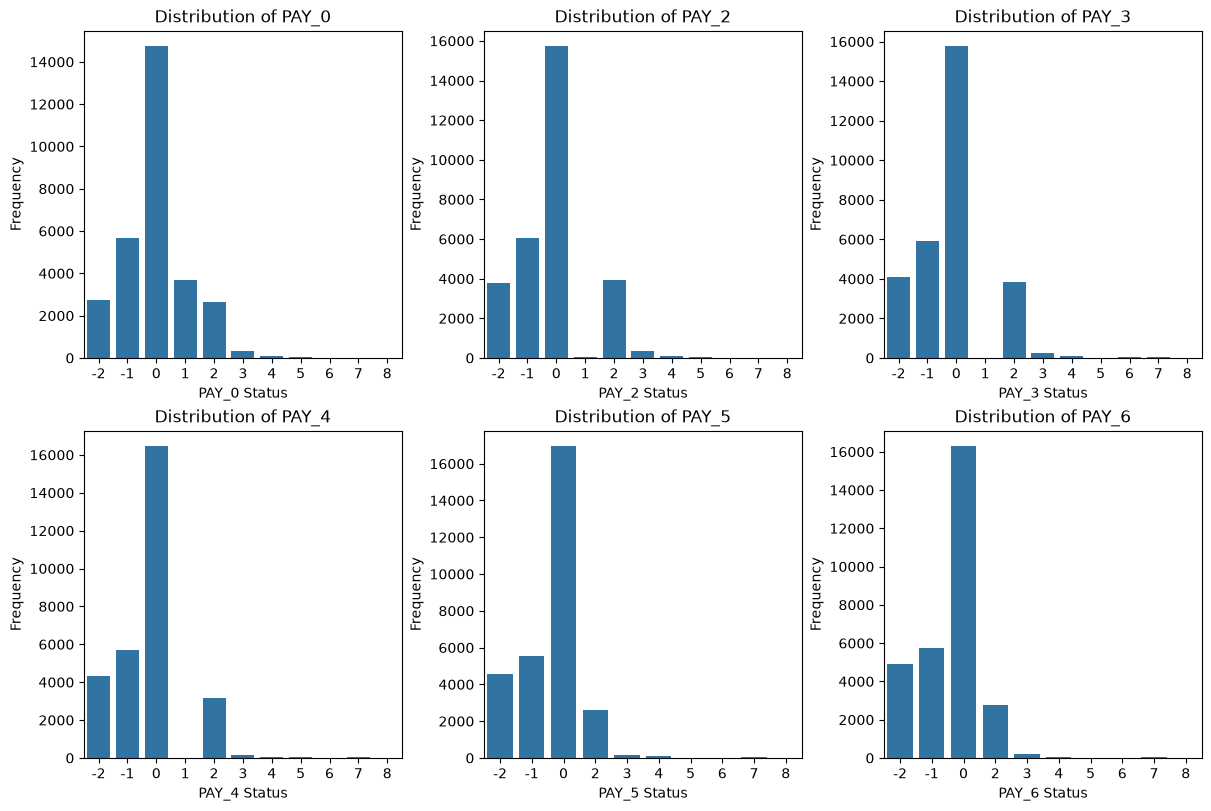

In [26]:
# Explore the distribution of the 'PAY_0', ... 'PAY_6' columns
pay_status_cols = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
plt.figure(figsize=(12, 8), constrained_layout=True)
for i, col in enumerate(pay_status_cols):
    plt.subplot(2, 3, i + 1)
    sns.countplot(x=col, data=df)
    plt.title(f'Distribution of {col}')
    plt.xlabel(f'{col} Status')
    plt.ylabel('Frequency')

Around half of the customers have a payment status of 0 (the use of revolving credit), one third of them have a payment status of -1 (paid in full) or -2 (no consumption), and the remaining customers have a payment status of 1, or 2 (delayed for 1 or 2 months, respectively).

There are very few occurences of payment delays for more than 3 months. It is also worth noting that the distribution of the `PAY_0` column is slightly different from the other columns, as it has a higher frequency of customers with a status of 1 (payment delay for 1 month).

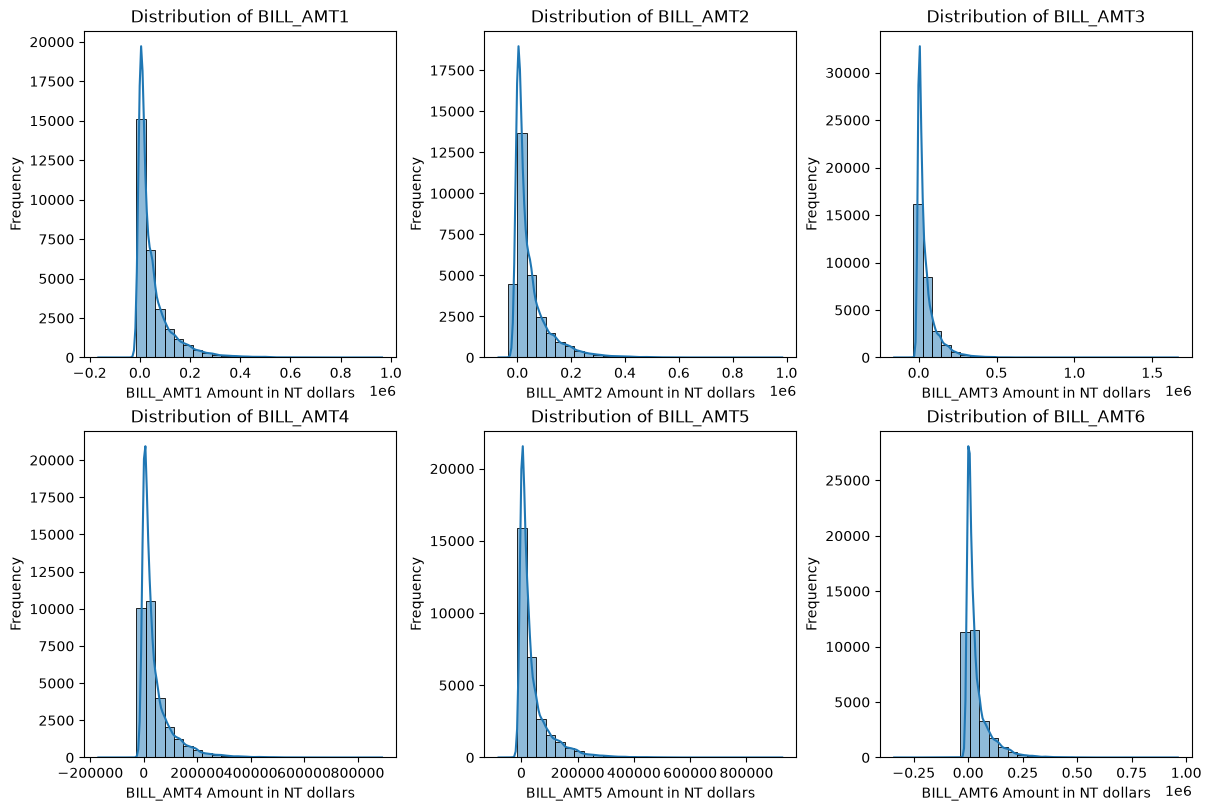

In [27]:
# Explore the distribution of the 'BILL_AMT1', ..., 'BILL_AMT6' columns
bill_amt_cols = ['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']
plt.figure(figsize=(12, 8), constrained_layout=True)
for i, col in enumerate(bill_amt_cols):
    plt.subplot(2, 3, i + 1)
    sns.histplot(df[col], bins=30, kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(f'{col} Amount in NT dollars')
    plt.ylabel('Frequency')

As we've seen previously, the `BILL_AMT1` to `BILL_AMT6` columns contain negative values, which are inconsistent with the expected behavior of bill amounts even if their frequency is not high. Further investigation and data cleaning may be necessary to address these inconsistencies before proceeding with any analysis or modeling.

Other than the negative values, the distributions of the bill amounts appear to be right-skewed, with a majority of customers having lower bill amounts and a smaller number of customers having higher bill amounts. This was somewhat expected, as we have already seen that the distribution of the `LIMIT_BAL` column is also right-skewed, and the `BILL_AMT` columns are likely to be correlated with the `LIMIT_BAL` column.

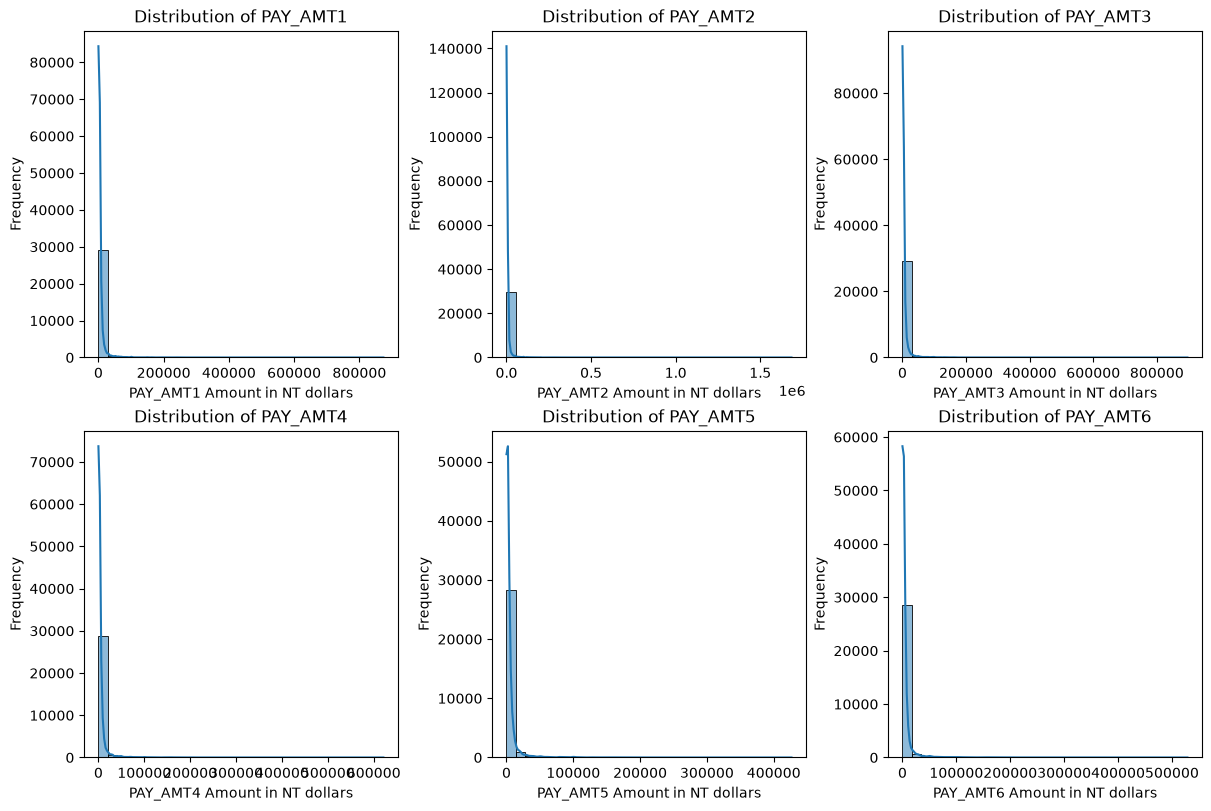

In [28]:
# Explore the distribution of the 'PAY_AMT1', ..., 'PAY_AMT6' columns
pay_amt_cols = ['PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']
plt.figure(figsize=(12, 8), constrained_layout=True)
for i, col in enumerate(pay_amt_cols):
    plt.subplot(2, 3, i + 1)
    sns.histplot(df[col], bins=30, kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(f'{col} Amount in NT dollars')
    plt.ylabel('Frequency')

Looking at the distributions of the `PAY_AMT` columns, we can observe that most customers have relatively low payment amounts, with a few customers making significantly higher payments. This indicates that while the majority of customers are making small payments, there are some outliers who are paying much larger amounts. It is also worth noting that the distributions of the `PAY_AMT` columns, compared to the `BILL_AMT` columns, show a more concentrated distribution around lower values, suggesting that customers are generally paying off only a portion of their outstanding bills each month.

# 7. Relationships with Default

We investigate whether there are relationships between individual features and default status.

Text(0.5, 1.0, 'Relationship between Credit Limit (LIMIT_BAL) and Default Status')

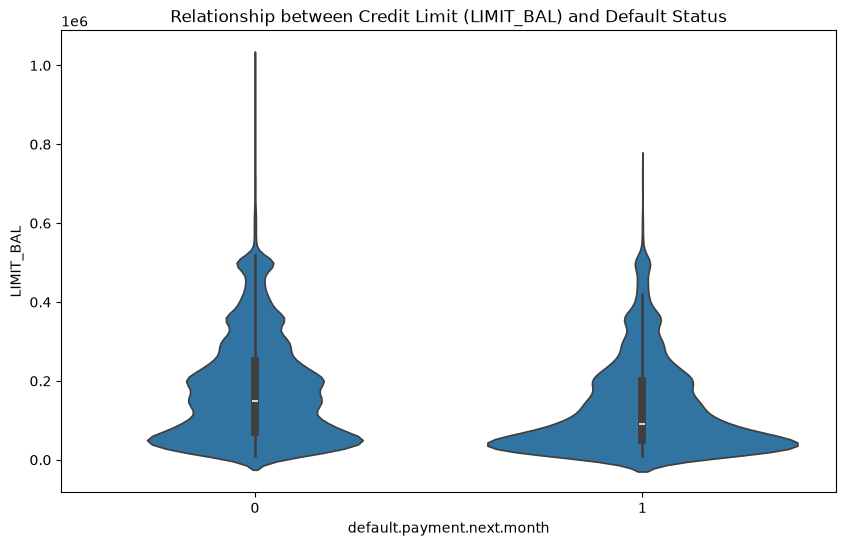

In [29]:
# Investigate the relationship between 'LIMIT_BAL' and 'default.payment.next.month'
plt.figure(figsize=(10, 6))
sns.violinplot(x='default.payment.next.month', y='LIMIT_BAL', data=df)
plt.title('Relationship between Credit Limit (LIMIT_BAL) and Default Status')   

The customers who defaulted on their payments tend to have lower credit limits compared to those who did not default. This suggests that customers with lower credit limits may be at a higher risk of defaulting on their payments.

Text(0.5, 0, '1 = Male, 2 = Female')

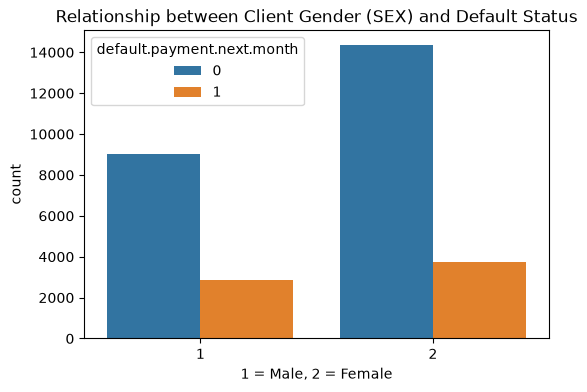

In [30]:
# Relationship between 'SEX' and 'default.payment.next.month'
plt.figure(figsize=(6, 4))
sns.countplot(x='SEX', hue='default.payment.next.month', data=df)
plt.title('Relationship between Client Gender (SEX) and Default Status')
plt.xlabel('1 = Male, 2 = Female')

We can observe that the distribution of defaulted and non-defaulted customers is relatively similar for both male and female clients, but there are slightly more defaulted male clients compared to female clients. This suggests that gender may have a minor influence on the likelihood of defaulting on payments, but further statistical analysis would be needed to confirm any significant relationship.

Text(0.5, 0, '1 = Graduate School, 2 = University, 3 = High School, 0, 4, 5, 6 = Others')

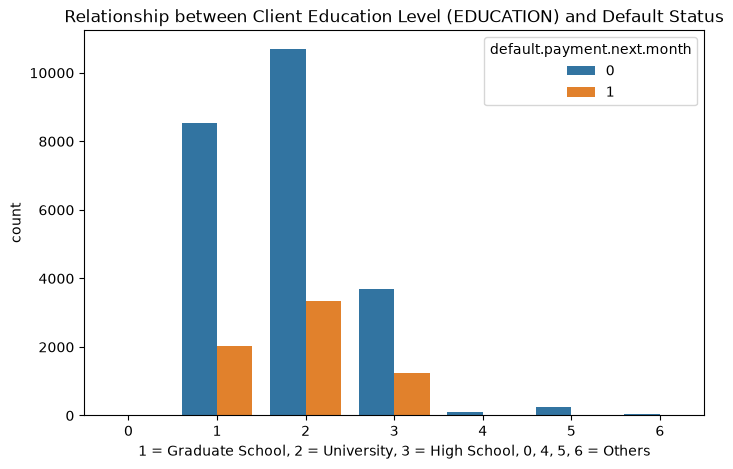

In [31]:
# Relationship between 'EDUCATION' and 'default.payment.next.month'
plt.figure(figsize=(8, 5))
sns.countplot(x='EDUCATION', hue='default.payment.next.month', data=df)
plt.title('Relationship between Client Education Level (EDUCATION) and Default Status')
plt.xlabel('1 = Graduate School, 2 = University, 3 = High School, 0, 4, 5, 6 = Others')

It appears that clients with higher education levels (Graduate School and University) have a lower default rate compared to those with lower education levels (High School, Others). This suggests that education level may be a significant factor in predicting default risk.

Text(0.5, 0, '1 = Married, 2 = Single, 3 = Divorced, 0 = Others')

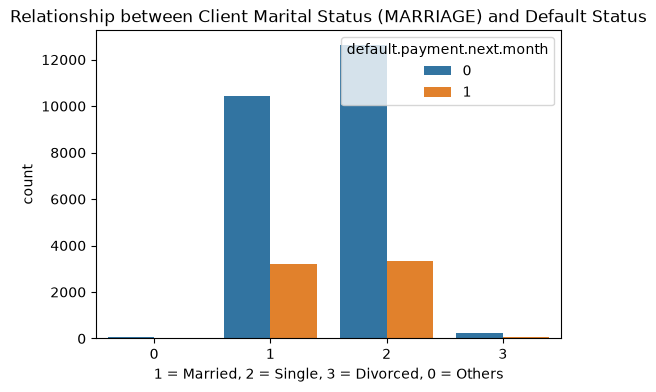

In [32]:
# Relationship between 'MARRIAGE' and 'default.payment.next.month'
plt.figure(figsize=(6, 4))
sns.countplot(x='MARRIAGE', hue='default.payment.next.month', data=df)
plt.title('Relationship between Client Marital Status (MARRIAGE) and Default Status')
plt.xlabel('1 = Married, 2 = Single, 3 = Divorced, 0 = Others')


The relationship between `MARRIAGE` and `defulat.payment.next.month` suggests that marital status may have an impact on the likelihood of defaulting on a payment. The clients who are single seem to have a lower default rate compared to those who are married.

Text(0.5, 1.0, 'Relationship between Client Age (AGE) and Default Status')

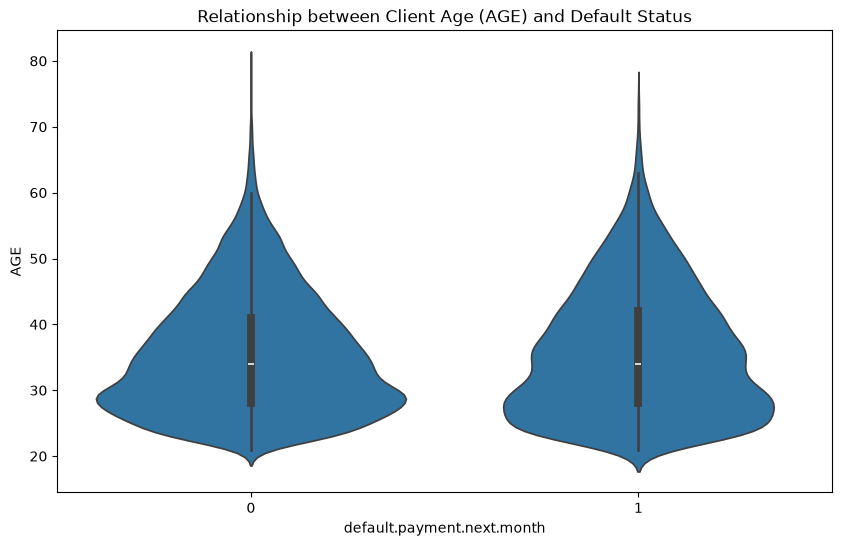

In [33]:
# Relationship between 'AGE' and 'default.payment.next.month'
plt.figure(figsize=(10, 6))
sns.violinplot(x='default.payment.next.month', y='AGE', data=df)
plt.title('Relationship between Client Age (AGE) and Default Status')

There seems to be no significant difference in the age distribution between defaulted and non-defaulted customers, as the median ages are quite similar. However, the age distribution of the non-defaulted customers is more right-skewed, with a higher concentration of younger customers, while the age distribution of the defaulted customers is more uniform across different age groups.

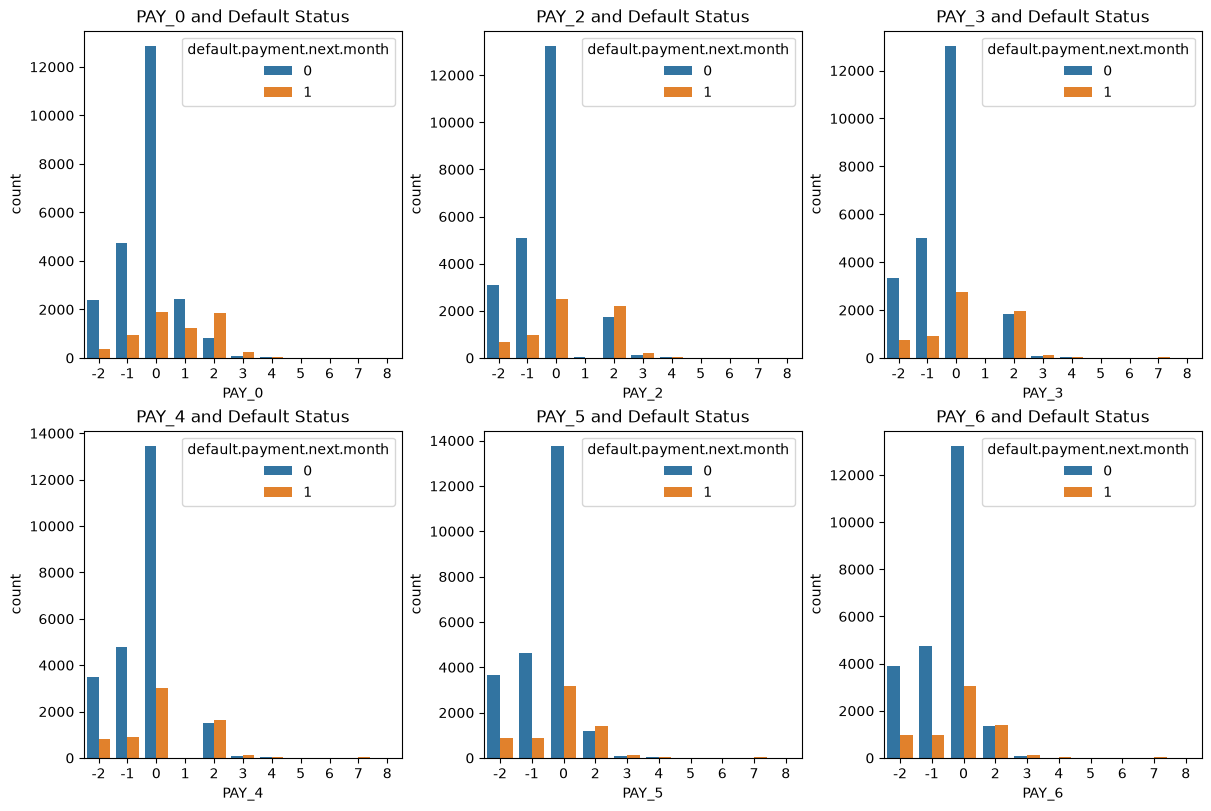

In [34]:
# Relationship between 'PAY_0', ..., 'PAY_6' and 'default.payment.next.month'
plt.figure(figsize=(12, 8), constrained_layout=True)
for i, col in enumerate(pay_status_cols):
    plt.subplot(2, 3, i + 1)
    sns.countplot(x=col, hue='default.payment.next.month', data=df)
    plt.title(f'{col} and Default Status')

According to the relationship between the repayment status columns (`PAY_0`, `PAY_2`, `PAY_3`, `PAY_4`, `PAY_5`, `PAY_6`) and the default status, we can observe that as the repayment status worsens (i.e., higher positive values indicating more delayed payments), the proportion of customers who default increases. This may imply that the customers who make late payments (especially those who with a delay of 2 months or more) are more likely to default on their payments in the next month.

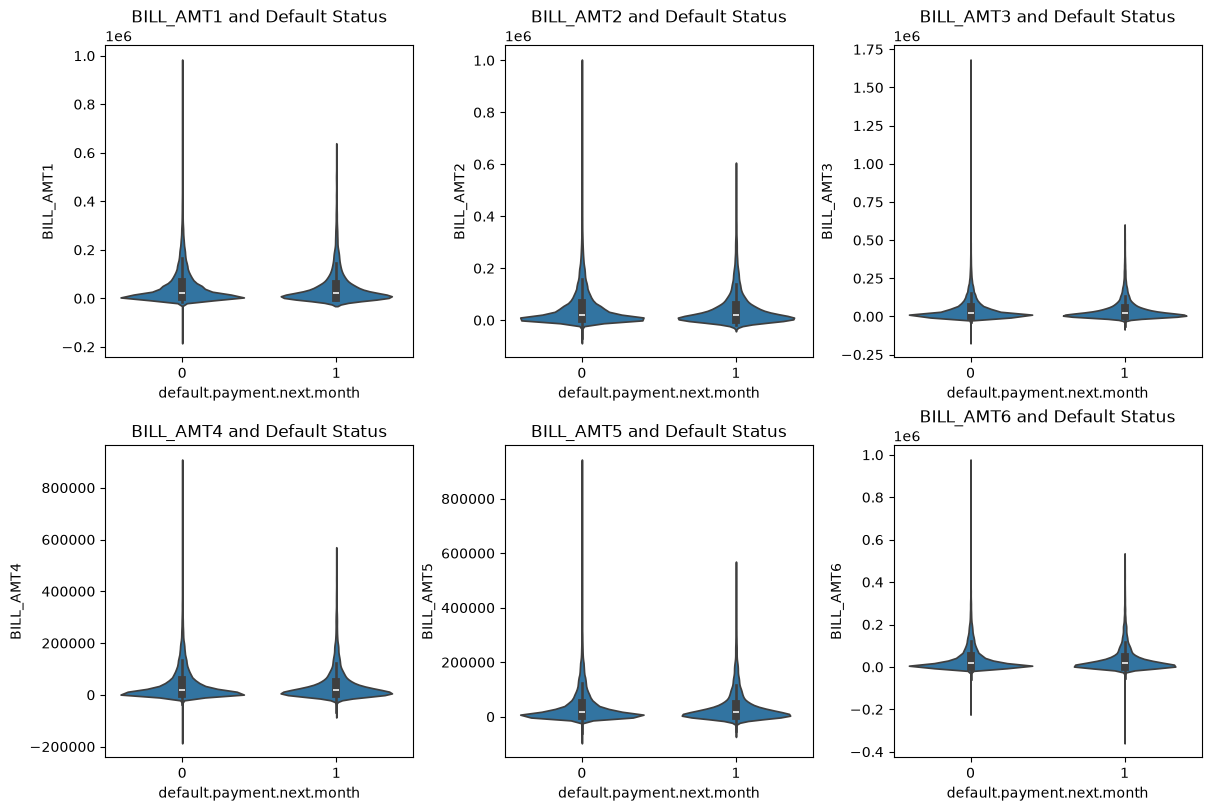

In [35]:
# Relationship between 'BILL_AMT1', ..., 'BILL_AMT6' and 'default.payment.next.month'
plt.figure(figsize=(12, 8), constrained_layout=True)
for i, col in enumerate(bill_amt_cols):
    plt.subplot(2, 3, i + 1)
    sns.violinplot(x='default.payment.next.month', y=col, data=df)
    plt.title(f'{col} and Default Status')

Regardless of the default status, the distributions of the bill amounts are right-skewed, with a few customers having very high bill amounts. However, the distribution of the bill amounts for non-defaulted customers tends to have a longer tail, indicating that some non-defaulted customers have very high bill amounts.

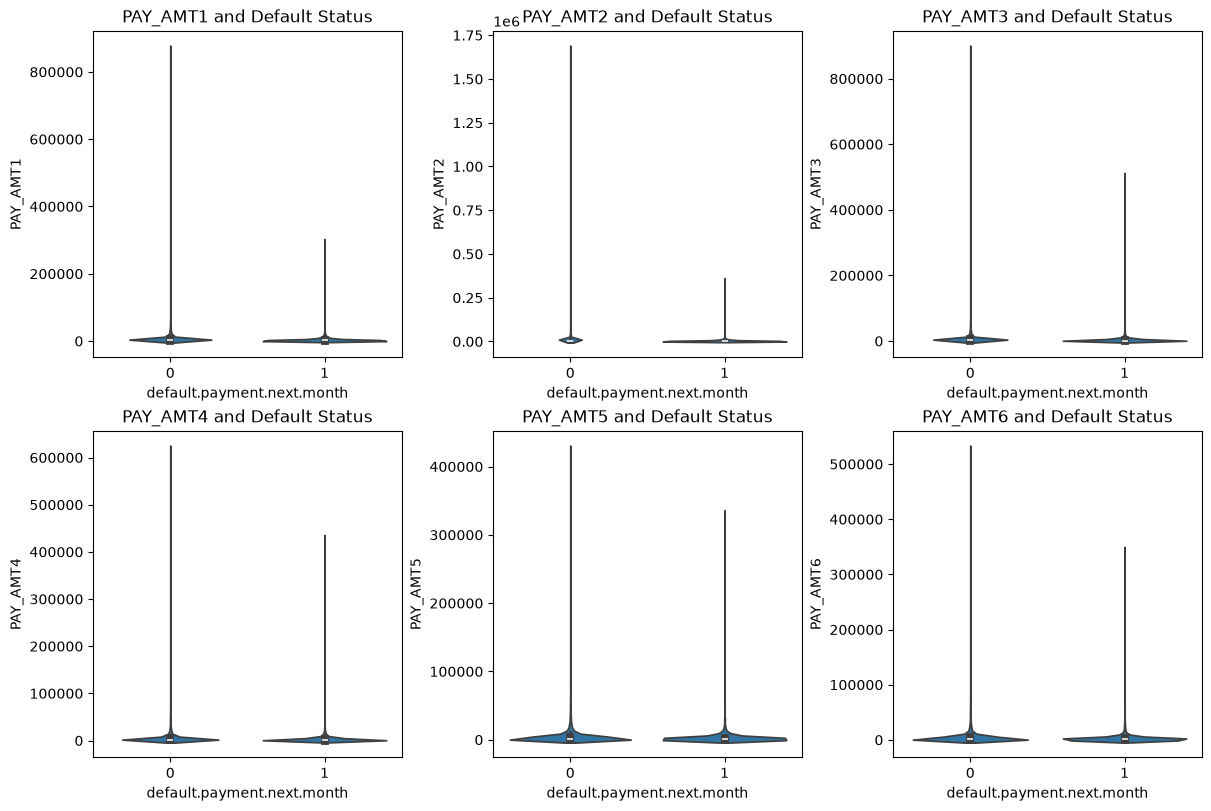

In [36]:
# Relationship between 'PAY_AMT1', ..., 'PAY_AMT6' and 'default.payment.next.month'
plt.figure(figsize=(12, 8), constrained_layout=True)
for i, col in enumerate(pay_amt_cols):
    plt.subplot(2, 3, i + 1)
    sns.violinplot(x='default.payment.next.month', y=col, data=df)
    plt.title(f'{col} and Default Status')

As in the distribution between 'BILL_AMT1', ..., 'BILL_AMT6' and 'default.payment.next.month', we observe that the distributions of 'PAY_AMT1', ..., 'PAY_AMT6' are also right-skewed, with a few extreme values, regardless of the default status. This indicates that most customers make relatively small payments, while a few customers make significantly larger payments.

<Axes: >

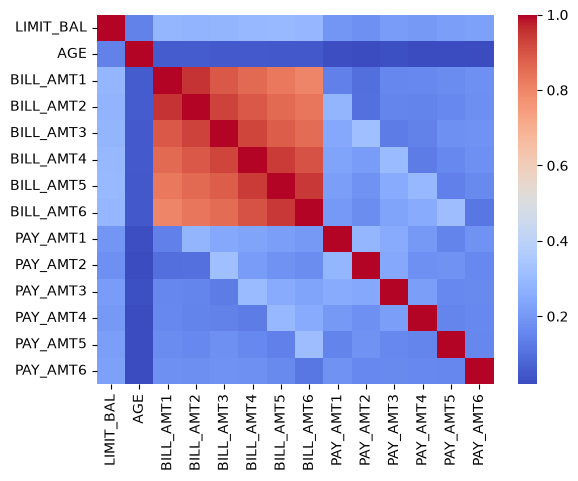

In [38]:
# Correlation matrix for numerical features
numerical_features = ['LIMIT_BAL', 'AGE'] + bill_amt_cols + pay_amt_cols
correlation_matrix = df[numerical_features].corr()
sns.heatmap(correlation_matrix, fmt=".2f", cmap='coolwarm', cbar=True)

Looking at the correaltion matrix between numerical features, we can see that there are some strong correlations between certain features. For example, the bill amounts (`BILL_AMT1` to `BILL_AMT6`) are highly correlated with each other. However, these strong correlations are not observed among the payment amounts (`PAY_AMT1` to `PAY_AMT6`). This suggests that while the bill amounts may be related to each other, the payment amounts may not have a strong relationship with each other.

In addition, one can also would have thought that the bill amount would have a strong correlation with payment amount features. However, the correlation matrix shows that these features have a weak correlation with each other. This suggests that the bill amount and payment amount features may not be as closely related as one might expect, and that other factors may be influencing the relationship between these features.

# 8. Identify Risks before Modeling

## 8.1. Target Class Imbalance

The target variable `default.payment.next.month` represents whether a client defaults on payment in the following month.

We have seen previously that the target has an unequal distribution between default and non-default observations; only 22 percent of the total clients are in default.

This imbalance in the two classes can affect model training and evaluation because a model that predominantly predicts the majority class may achieve relatively high accuracy while failing to identify clients who default.

**Modeling considerations:**

- Use stratified sampling to preserve the target distribution across training, validation, and test sets.
- Evaluate models using metrics beyond accuracy, including precision, recall, F1-score, ROC-AUC, and PR-AUC.
- Consider the trade-off between identifying default cases and generating false alarms.
- Investigate class weighting or resampling techniques if necessary, using training data only.

## 8.2. Feature Representation and Categorical Encoding

Although several variables are stored as numerical values, their underlying meaning is categorical or ordinal.

Demographic variables such as education and marital status use numerical codes to represent distinct categories. Similarly, repayment-status variables represent different levels of payment delay.

Treating all these variables as continuous numerical features could introduce inappropriate assumptions about the relationships between their encoded values.

**Modeling considerations:**

- Treat demographic variables as categorical features.
- Investigate the appropriate representation of repayment status, considering its ordinal nature.
- Compare alternative encodings where appropriate.

## 8.3. Inconsistency

The dataset contains some inconsistencies, such as the presence of negative values in the `BILL_AMT` and `PAY_AMT` columns, which are not realistic for bill amounts and payment amounts. 

These inconsistencies should be addressed during the data cleaning process to ensure the quality of the dataset for further analysis and modeling.

**Modeling Considerations:**
- Address the inconsistencies in the dataset. This may involve replacing invalid values with appropriate categories, removing or imputing negative values, and ensuring that the data is clean and reliable.

## 8.4. Outliers

Financial variables may exhibit skewed distributions and extreme values due to differences in clients' credit limits, outstanding balances and payment behavior.

These observations are not necessarily data errors. Removing them indiscriminately could eliminate relevant information about higher-risk clients.

**Modeling considerations:**

- Investigate extreme values and validate their plausibility.
- Distinguish genuine financial extremes from invalid values.
- Avoid automatic outlier removal or arbitrary capping.
- Consider transformations or robust modeling approaches
  where appropriate.


## 8.5. Representativeness and Fairness

The dataset includes demographic characteristics such as age, sex, education and marital status.

Although these variables may contain predictive information, their use in credit risk assessment requires careful consideration from a fairness and regulatory perspective.

Furthermore, the dataset represents a specific population of credit card clients in Taiwan, rather than a representative sample of all banking customers.

**Modeling considerations:**

- Examine differences in default rates across demographic groups.
- Evaluate model performance across relevant subgroups.
- Consider the implications of including demographic variables in the predictor set.
- Document limitations regarding population representativeness and generalizability to other markets.


## 8.6. Data Leakage and Temporal Consistency

In credit risk modeling, predictors must only contain information available at the time the prediction is made.

Since the objective is to predict default in the following month, it is important to verify that all explanatory variables represent historical information rather than information observed during or after the target period.

The dataset includes monthly repayment statuses, bill amounts and payment amounts. Their temporal definitions must therefore be reviewed to ensure that no information from the target period is included in the predictors.

**Modeling decision:**

- Exclude the target variable from all predictors.
- Exclude the client identifier (`ID`).
- Verify the temporal reference of all monthly variables using the original dataset documentation.
- Document any uncertainty regarding feature availability.


# 9. Modeling Preparation

## 9.1. Target and Feature Definition

The target variable is `default.payment.next.month`, which indicates whether a customer will default on their credit card payment next month (1 = default, 0 = non-default). 

The initial feature set include all remaining varaibles, except `ID`, which is a unique identifier for each customer and does not provide predictive information. Some features may be removed or transformed during the feature engineering process based on their relevance and predictive power.

## 9.2. Feature Treatment Strategy

The following feature treatment strategies will be applied to the dataset:

- **Identifier**: The `ID` column will be dropped as it does not provide any predictive value for the target variable.
- **Demographics**: The categorical features `SEX`, `EDUCATION`, and `MARRIAGE` will be treated as categorical variables. The `LIMIT_BAL` and `AGE` columns will be subject to feature scaling and normalization as they are numerical variables.
- **Repayment history**: The repayment status features `PAY_0`, `PAY_2`, `PAY_3`, `PAY_4`, `PAY_5`, and `PAY_6` will be treated as categorical variables. These features will be encoded appropriately for modeling.
- **Bill amounts**: The bill amount features `BILL_AMT1`, `BILL_AMT2`, `BILL_AMT3`, `BILL_AMT4`, `BILL_AMT5`, and `BILL_AMT6` will be treated as numerical variables. The negative values in these columns will be handled after further analysis of their distributions and relationships with the target variable. These features will be subject to feature scaling and normalization as they are numerical variables.
- **Payment amounts**: The payment amount features `PAY_AMT1`, `PAY_AMT2`, `PAY_AMT3`, `PAY_AMT4`, `PAY_AMT5`, and `PAY_AMT6` will be treated as numerical variables. The negative values in these columns will be handled after further analysis of their distributions and relationships with the target variable. These features will be subject to feature scaling and normalization as they are numerical variables.

## 9.3. Data Splitting Strategy

The dataset will be split into training (70%), validation (15%), and test (15%) sets to ensure robust model evaluation. The splitting will be done in a stratified manner to maintain the distribution of the target variable across all sets. A fixed random seed will also be used for reproducibility of the code.

## 9.4. Evaluation Strategy

The following metrics will be used to assess the performance of the model:

- **ROC-AUC**: Overall ranking/discrimination ability
- **PR-AUC**: Performance in identifying the minority default class
- **Recall**: Ability to identify actual defaults
- **Precision**: Reliability of predicted defaults
- **F1-score**: Balance between precision and recall
- **Confusion matrix**: Understand types of classification errors

The threshold selection will be based on business trade-offs rather than automatically using 0.5.



## 10. Key Findings and Next Steps

### Key Findings
- The dataset contains 30,000 observations and 23 explanatory variables covering client demographics, credit limits, repayment history, bill amounts and payment amounts.
- Approximately 22% of clients defaulted on payment in the following month, indicating a moderate class imbalance.
- Repayment history appears particularly relevant for understanding default behavior.
- Some numerical variables represent categorical or ordinal information and require appropriate feature treatment.
- The dataset contains historical observations from Taiwan (2005), limiting its direct generalizability to other markets and periods.

### Modeling Considerations
- Exclude client identifiers and ensure all predictors are available at the prediction date.
- Apply appropriate encoding strategies for categorical and ordinal variables.
- Preserve the target distribution through stratified data splitting.
- Evaluate model performance using metrics beyond accuracy, with particular attention to default identification and fairness.

### Next Steps
- Develop baseline classification models.
- Evaluate model performance using appropriate classification metrics.
- Investigate feature importance and model explainability.